In [1]:
# Import Libraries and Load Data
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import auc, roc_auc_score, roc_curve, silhouette_score
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)

# Load dataset
df = pd.read_csv("titanic_cleaned.csv")
X = df.drop(columns=["Survived"])
y = df["Survived"]

print("Feature matrix shape:", X.shape)
X.head()

Feature matrix shape: (891, 8)


,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,-0.565736,1,0,-0.502445,1,0,1
1,1,0.663861,1,0,0.786845,0,0,0
2,3,-0.258337,0,0,-0.488854,0,0,1
3,1,0.433312,1,0,0.420730,0,0,1
4,3,0.433312,0,0,-0.486337,1,0,1


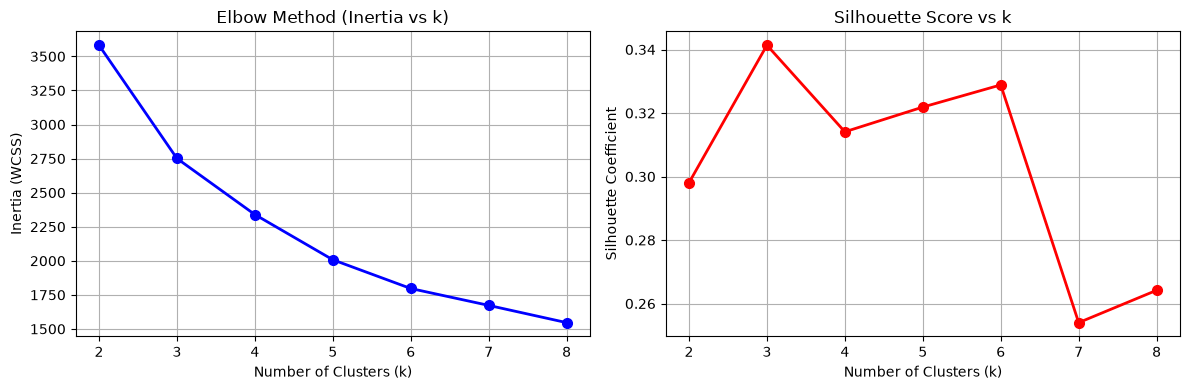

k = 2 | Silhouette Score: 0.2981
k = 3 | Silhouette Score: 0.3414
k = 4 | Silhouette Score: 0.3141
k = 5 | Silhouette Score: 0.3219
k = 6 | Silhouette Score: 0.3289
k = 7 | Silhouette Score: 0.2540
k = 8 | Silhouette Score: 0.2642


In [2]:
# K-Means Clustering- Elbow Method & Silhouette Analysis
# Since clustering is unsupervised, we find the optimal cluster count k by analysing:
# Inertia (Within-Cluster Sum of Squares- WCSS): Lower is tighter clusters; look for an "elbow" inflection point
# Silhouette Score: Ranges from -1 to +1; higher indicates well-separated, distinct clusters.

wcss = []
silhouette_scores = []
k_range = range(2, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, cluster_labels))

# Plot Elbow and Silhouette curves side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_range, wcss, "bo-", linewidth=2, markersize=7)
axes[0].set_title("Elbow Method (Inertia vs k)")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].grid(True)

axes[1].plot(k_range, silhouette_scores, "ro-", linewidth=2, markersize=7)
axes[1].set_title("Silhouette Score vs k")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Coefficient")
axes[1].grid(True)

plt.tight_layout()
plt.show()

for k, score in zip(k_range, silhouette_scores):
    print(f"k = {k} | Silhouette Score: {score:.4f}")

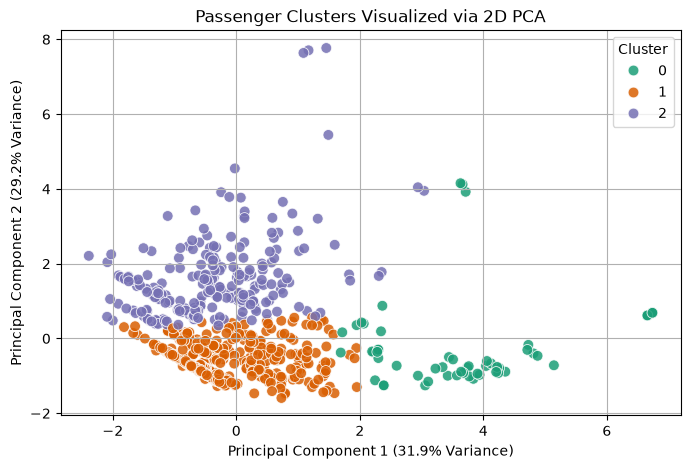

Total Variance Explained by 2 PCs: 61.06%


In [3]:
# Optimal K-Means Clustering & 2D PCA Visualization
# Run k= 3 (or Optimal k), reduce the 8-dimensional feature space to 2 prinvipal components using PCA< and plot the passenger clusters.

# Fit K-Means with chosen k=3
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
X_clustered = X.copy()
X_clustered["Cluster"] = kmeans_final.fit_predict(X)

# PCA to reduce 8 features down to 2 principal components for visualization
pca = PCA(n_components=2, random_state=42)
pca_transformed = pca.fit_transform(X)

X_clustered["PCA1"] = pca_transformed[:, 0]
X_clustered["PCA2"] = pca_transformed[:, 1]

# Plot PCA scatter plot colored by clusters
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=X_clustered,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="Dark2",
    s=60,
    alpha=0.85,
)
plt.title("Passenger Clusters Visualized via 2D PCA")
plt.xlabel(
    f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)"
)
plt.ylabel(
    f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)"
)
plt.grid(True)
plt.show()

print(
    f"Total Variance Explained by 2 PCs: {np.sum(pca.explained_variance_ratio_)*100:.2f}%"
)

In [5]:
# Cluster Profiling & Demographic Interpretation
# Examine what each cluster actually represents in real terms (average class, scaled fare, sex distribution)

# Unscale or inspect mean feature profiles across clusters
profile = (
    X_clustered.groupby("Cluster")[
        ["Pclass", "Age", "Fare", "Sex_male", "Embarked_S"]
    ]
    .mean()
    .round(2)
)
profile["Passenger_Count"] = (
    X_clustered["Cluster"].value_counts().sort_index()
)
print("=== Cluster Profile Summary ===")
display(profile)

=== Cluster Profile Summary ===


,Pclass,Age,Fare,Sex_male,Embarked_S,Passenger_Count
Cluster,,,,,,
0,2.83,-1.09,0.31,0.47,0.88,58
1,2.74,-0.21,-0.38,0.70,0.75,586
2,1.15,0.74,0.84,0.57,0.64,247


In [6]:
# 5-Fold Statified Cross-Validation on Random Forest 
# Validate that our Random Forest from Week 2 didn't just get lucky on a single train-test split, testing across 5 folds.

rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(rf_baseline, X, y, cv=cv, scoring="accuracy")

print("=== 5-Fold Cross-Validation Scores ===")
for fold_idx, score in enumerate(cv_scores, 1):
    print(f"Fold {fold_idx}: {score*100:.2f}%")

print(
    f"\nMean CV Accuracy: {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)"
)

=== 5-Fold Cross-Validation Scores ===
Fold 1: 85.47%
Fold 2: 80.90%
Fold 3: 80.34%
Fold 4: 82.58%
Fold 5: 83.15%

Mean CV Accuracy: 82.49% (+/- 1.82%)


In [7]:
# Hyperparameter Optimization with GridSearchCV
# Exhaustively test combinations of tree depth, estimator count, and split criteria to tune the model.

# Train-test split for final ROC-AUC evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Define parameter grid
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [4, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
print("=== GridSearchCV Results ===")
print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best 5-Fold F1-Score: {grid_search.best_score_*100:.2f}%")

=== GridSearchCV Results ===
Best Hyperparameters: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 50}
Best 5-Fold F1-Score: 76.72%


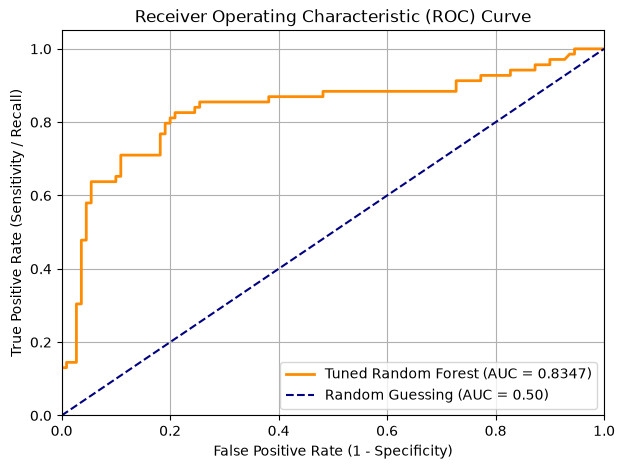

Final Test ROC-AUC Score: 0.8347


In [8]:
# ROC-AUC Curve & Evaluation
# The ROC curve graphs the True Positive Rate vs. False Positive Rate across allprobability threshold. An AUC closer to 1.0 indicates strong discriminative capability.

# Predict probabilities for the test partition
y_pred_proba = best_rf.predict_proba(X_test)[:, 1]

# Calculate ROC metrics
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC-AUC Curve
plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    color="darkorange",
    lw=2,
    label=f"Tuned Random Forest (AUC = {roc_auc:.4f})",
)
plt.plot(
    [0, 1],
    [0, 1],
    color="navy",
    lw=1.5,
    linestyle="--",
    label="Random Guessing (AUC = 0.50)",
)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"Final Test ROC-AUC Score: {roc_auc:.4f}")